# SynCOM: Synthetic Corona Outflow Model (v2-fixed)

This notebook runs the Python version of SynCOM step by step. Each function is introduced by two cells:
- **What it does / expected behaviour**: inputs, outputs and what you should see.
- **Physics in …**: the physics behind it, written as a short textbook chapter.

| chapter | function |
|---|---|
| 1 | `default_syncom_prams` |
| 2 | `syncom_load` and unit conversions |
| 3 | `gaussian_profile`, `gaussian_wave` |
| 4 | `syncom_image` |
| 5 | `syncom_core` |
| 6 | `save_syncom_movie` |
| 7 | `polar_to_rect`, `plot_rect_image`, `save_rect_movie` |

**Version v2-fixed.** This is the vectorised port of the IDL model. It has two known limitations, both fixed in **v3-periodic_blobs**:
1. Each blob has a fixed train of 7 copies that is never renewed, so the field empties over time.
2. Blobs start at about 9.9 R☉ instead of 5 R☉.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
from datetime import date

from punchbowl.data.visualize import cmap_punch

from syncom_prams import default_syncom_prams
from syncom_load import syncom_load
from gaussian_function import gaussian_wave
from syncom_image import syncom_image
from syncom_core import syncom_core
from syncom_path import syncom_output_path, syncom_run_dir, syncom_run_name
from syncom_movie import save_syncom_movie, save_rect_movie, plot_rect_image
from polar_to_rect import polar_to_rect


# 1. Parameters: `default_syncom_prams`

## What it does
`default_syncom_prams` (in `syncom_prams.py`) returns the dictionary of settings that every other SynCOM function reads. If `SAVEPRAMS` is given, it also saves them to a `.npy` file.

| key | default | meaning |
|---|---|---|
| `syncom_n_blobs` | 1000 | number of blobs (independent outflow sources) |
| `syncom_nx` | 3600 | pixels in position angle (0.1° each) |
| `syncom_ny` | 659 | pixels in radius |
| `syncom_pixel` | 0.0141876 R☉ | radial pixel size |
| `syncom_cadence` | 300 s | time between two frames |
| `syncom_initial_R_sun` | 5.0 R☉ | launch radius of the blobs |
| `syncom_scale_factor` | 2.0 | multiplies every blob size |
| `syncom_acc`, `syncom_noise_level`, `syncom_max_intensity` | 0, 0, 1e-14 | stored for compatibility with the IDL version; not used by the current image code |

## Expected behaviour
- The function returns a plain `dict` and prints where the parameters were saved.
- `DATE` changes only the labels (`Label`, `syncomfile`); it does not change the simulation.
- Every later cell takes its grid size, cadence and pixel size from this dictionary, so changing a value here changes the whole run.


## Physics in `default_syncom_prams`: the observing grid

### 1.1 A coronagraph image in polar coordinates
A coronagraph blocks the bright solar disk and records the faint white light that coronal electrons scatter toward the observer. The solar wind flows out almost radially, so the natural coordinates for the image are the **position angle** $\psi$ (the angle around the Sun in the plane of the sky) and the **heliocentric distance** $r$. SynCOM works directly on a polar grid:

$$
\psi_i = i\,\Delta\psi,\quad \Delta\psi = 0.1^\circ,\ i = 0\ldots 3599, \qquad
r_j = r_{\min} + j\,\Delta r,\quad j = 0\ldots 658 .
$$

The default sizes match the STEREO/COR2 deep-field campaigns (Howard et al. 2008; Kaiser et al. 2008). $\Delta r = 0.01419\,R_\odot \approx 9.87$ Mm, and the field runs from $r_{\min} = 5\,R_\odot$ (the bottom row, `POLAR_RHO_RANGE[0]`) outward.

### 1.2 Time sampling and the speed resolution
The images are snapshots taken every $\Delta t = 300$ s. A blob moving at speed $v$ advances

$$
\Delta j = \frac{v\,\Delta t}{\Delta r} \ \text{pixels per frame},
\qquad \frac{\Delta r}{\Delta t} = \frac{9874\ \text{km}}{300\ \text{s}} \approx 33\ \text{km s}^{-1}\ \text{per pixel per frame}.
$$

So a 300 km/s blob moves about 9 pixels between frames. Any flow-tracking method run on these images has to follow features over this step. Structures that repeat along the radius closer than about two steps can't be told apart from frame to frame. This is the spatial version of the Nyquist condition.

### 1.3 Field of view: two numbers that must agree
The radial size of the field is set in two places:
- The simulation uses `SYNCOM_PIXEL`: $(N_r-1)\,\Delta r = 658 \times 0.0141876 = 9.335\,R_\odot$.
- The plots and movies use `POLAR_RHO_RANGE` $= (5.0,\ 14.226)$, which is $9.226\,R_\odot$.

The two differ by 1.2%, so plotted radii and speeds come out 1.2% low. The comments in `syncom_prams.py` explain how to make them agree before a run.

### 1.4 Blob size
`syncom_scale_factor` multiplies the size of every blob (Chapter 2.4). Larger blobs overlap more, which gives a smoother, more diffuse corona. Smaller blobs give a grainier one.


In [2]:
params = default_syncom_prams(SYNCOM_N_BLOBS=5000,DATE="2023-04-11", SAVEPRAMS="syncom_params.npy")

params

Saved SYNCOM parameters to: syncom_params.npy


{'Name': 'syncom',
 'Label': 'SynCOM model, cube=2023-04-11\nobserver date=2023-04-11',
 'filename': '/Users/valmirmoraesfilho/stereo_analysis.sav',
 'syncom_cadence': 300.0,
 'syncom_pixel': 0.0141875720451562,
 'syncom_n_blobs': 5000,
 'syncom_acc': 0,
 'syncom_time': 0.0,
 'syncom_nx': 3600,
 'syncom_ny': 659,
 'syncom_initial_R_sun': 5.0,
 'syncom_scale_factor': 2.0,
 'syncom_noise_level': 0.0,
 'syncom_max_intensity': 1e-14,
 'syncomfile': 'syncom_20230411_densfix.sav'}

In [3]:
n_blobs = params["syncom_n_blobs"]
nx = params["syncom_nx"]
ny = params["syncom_ny"]
scale_factor = params["syncom_scale_factor"]
pixel_size = params["syncom_pixel"]
cadence = params["syncom_cadence"]
Rsun2Km = 696000.0
spatial_scale = Rsun2Km * pixel_size

# 2. Blob properties: `syncom_load`

## What it does
`syncom_load(params, simple=True)` (in `syncom_load.py`) creates `syncom_n_blobs` blobs and gives each one:
- a **position angle** $\psi$, drawn at random (`generate_blob_positions`)
- a **speed** $v$, **period** $P$ and **size** $L$, read from profiles that depend only on the position angle (`load_velocity_profile`, `assign_blob_properties`)

The blobs are sorted from fastest to slowest and returned as `outarray` (one row per blob):

| column | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| content | launch radius [R☉] | φ [rad] | θ [rad] | group counter (not used by the images) | period [s] | speed [km/s] | size | ψ [0.1° pixels] |

## Expected behaviour
- `outarray.shape == (n_blobs, 8)`.
- The results are reproducible, because of the fixed random seeds (22 for the profiles, 123 for the positions).
- With `simple=True`: speeds are 150–350 km/s, periods are 5400–10800 s (1.5–3 h), and sizes are 0.1–1.1.
- With `simple=False`: the profiles are read from `velocity.npy` and `frequency.npy`, which must be in the working directory.


## Physics in `syncom_load`: where the blobs come from

### 2.1 Blobs in the slow solar wind
White-light coronagraphs show the slow solar wind as a stream of small density enhancements, or "blobs", released from the tips of helmet streamers. The blobs move outward and speed up to a few hundred km/s (Sheeley et al. 1997). Remote and in-situ observations also show that these structures are often **quasi-periodic**, with characteristic periods of about 1–3 hours (Viall & Vourlidas 2015). SynCOM represents this outflow as a set of independent sources. Each source has a fixed position angle, speed, period and size.

### 2.2 Speed versus position angle
With `simple=True` the speed is a two-sector profile:

$$
v(\psi) = 250 + 100\cos\!\left(2\psi\right)\ \ \text{km s}^{-1}, \qquad 150 \le v \le 350\ \text{km s}^{-1}.
$$

It peaks at $\psi = 0^\circ$ and $180^\circ$, and is lowest at $90^\circ$ and $270^\circ$. That is the $m = 2$ pattern of a simple dipole-like corona, with two faster and two slower sectors around the Sun. Because the speed is known exactly at every position angle, SynCOM images are a controlled test for speed-measuring methods (time-delay correlation, FlowTrack): the "true" answer is this curve.

### 2.3 Period
Each 0.1° bin gets a random period $P \in [1.5, 3]$ h, matching the time scales of the periodic density structures above. The period is the time between two releases of the same blob (see `syncom_image`).

### 2.4 Size
Each bin also gets a random size $s \in [0.1, 1.1]$. The image code turns this into a Gaussian width $L = \text{scale}\cdot s / 0.1$ pixels. With scale 2, that's $L = 2$–$22$ px, i.e. 0.2°–2.2° in angle and $2L = 0.06$–$0.62\,R_\odot$ in radius.

### 2.5 Position angles
A blob leaves the Sun in a 3D direction (colatitude $\theta$, longitude $\phi$). The coronagraph only sees its projection onto the plane of the sky. `generate_blob_positions` draws $\theta \in [0^\circ, 180^\circ)$ and $\phi \in [0^\circ, 360^\circ)$ and maps them to the position angle:

$$
\psi = \begin{cases} 360^\circ - \theta & \sin\phi \ge 0 \\ \theta & \sin\phi < 0 \end{cases}
$$

The sign of $\sin\phi$ decides which limb (east or west) the blob is seen on. Since $\theta$ is uniform, the blobs are spread evenly in position angle.


In [4]:
# Load with sinusoidal velocity profile
load_struc = syncom_load(params, simple=True)
outarray = load_struc["outarray"]

# Check shape
print(outarray.shape)

(5000, 8)


## Unit conversions (from physical units to pixels and frames)
The image code works in **pixels** and **frames**, so the next cell converts each blob's properties:

| quantity | formula | unit |
|---|---|---|
| start radius | `radial_i = R / pixel_size` | px |
| speed | `v_array = v · cadence / (R☉ · pixel_size)` | px/frame |
| period | `period_array` (kept in seconds; `syncom_image` divides by the cadence) | s |
| size | `L_array = scale · s / 0.1` | px |
| position angle | `PSI` | 0.1° px |
| phase | `time_0` uniform 1–201 | frames |

Note that `radial_i = 5 / 0.01419 = 352` px measures 5 R☉ from the **centre of the Sun**. The image's pixel 0 is already 5 R☉, so in v2 the blobs start at about 9.9 R☉. This is fixed in v3-periodic_blobs.


In [5]:
time_0 = np.random.default_rng(22).uniform(1.0, 201.0, n_blobs)
radial_i = outarray[:, 0] / pixel_size
period_array = outarray[:, 4]
v_array = (outarray[:, 5] * cadence) / spatial_scale  # pixels/frame
L_array = scale_factor * outarray[:, 6] / 0.1
PSI = outarray[:, 7]    

# 3. The blob shape: `gaussian_profile` and `gaussian_wave`

## What it does
`gaussian_function.py` provides two functions:
- `gaussian_profile(npixel, avr, st_dev, periodic=False)` is a 1D Gaussian of peak 1 centred at `avr` with width `st_dev` (in pixels). It's vectorised: give arrays of centres and widths and it returns one profile per blob. With `periodic=True` the axis wraps around.
- `gaussian_wave(npixel, avr, st_dev)` is a single 1D or 2D blob. In 2D it's the outer product of a **periodic** profile along position angle and a **non-periodic** profile along radius.

## Expected behaviour
- Peak value 1 at the centre. At ±1 width it's $e^{-1/2} \approx 0.61$.
- Along position angle, a blob centred near 359.9° continues at 0°, with no cut at the edge.
- Along radius, a blob near the top of the image is cut off at the edge (material leaves the field).
- The next cell draws one 2D blob at the centre of the grid.


## Physics in `gaussian_profile`: the shape of a blob

### 3.1 Brightness is linear in density
In white light, the corona is optically thin. Each electron Thomson-scatters a fraction of the photospheric light, and the observed brightness is an integral of the electron density $n_e$ along the line of sight $\ell$:

$$
B(\psi, r) \propto \int n_e(\ell)\, G(\ell)\, d\ell ,
$$

where $G$ is the Thomson scattering geometry factor. Since $B$ is **linear** in $n_e$, the image of many blobs is just the sum of the images of each blob. This is why SynCOM can build a frame by adding Gaussians.

### 3.2 Why a Gaussian
A blob is a localised density enhancement with no sharp edges. The Gaussian is the simplest smooth, localised profile with a single width parameter:

$$
g(x) = \exp\!\left[-\frac{(x - x_0)^2}{2\sigma^2}\right],\qquad \text{FWHM} = 2\sqrt{2\ln 2}\,\sigma \approx 2.355\,\sigma .
$$

In 2D the blob is separable:

$$
b(\psi, r) = \exp\!\left[-\frac{d_\psi(\psi,\psi_0)^2}{2L^2}\right]\exp\!\left[-\frac{(r - r_c)^2}{2(2L)^2}\right].
$$

Its radial width $2L$ is twice its angular width $L$, so blobs are **elongated along the flow**, as observed streamer blobs are.

### 3.3 Two kinds of boundary
Position angle lives on a circle. The distance between two angles is the shorter arc,

$$
d_\psi(\psi,\psi_0) = \big((\psi - \psi_0 + 180^\circ) \bmod 360^\circ\big) - 180^\circ ,
$$

so the image has no seam at 0°/360°. Radius is an **open** boundary. Material crosses the top of the field and is gone. It must not wrap back to the bottom, which `np.roll` in earlier versions did.


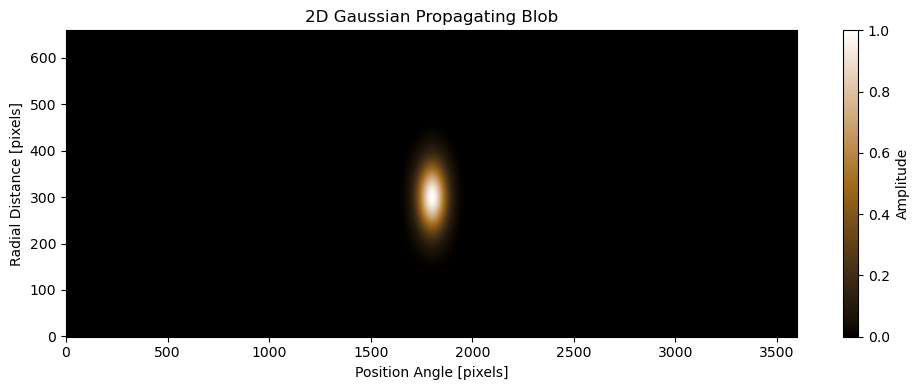

In [6]:
# Parameters for 2D Gaussian blob
npixel = [3600, 659]         # Image dimensions: [position angle, radial distance]
center = [1800, 300]          # Center position of the Gaussian blob
st_dev = [50, 50]            # Standard deviation in each direction

# Generate the 2D Gaussian profile
blob = gaussian_wave(npixel, center, st_dev)

# Plot the result
plt.figure(figsize=(10, 4))
plt.imshow(blob.T, origin='lower', aspect='auto', cmap=cmap_punch)
plt.colorbar(label='Amplitude')
plt.title('2D Gaussian Propagating Blob')
plt.xlabel('Position Angle [pixels]')
plt.ylabel('Radial Distance [pixels]')
plt.tight_layout()
plt.show()

# 4. One synthetic image: `syncom_image`

## What it does (v2-fixed)
`syncom_image(params, syncom_version, scalefactor, time_0, radial_i, v_array, period_array, L_array, PSI, time_t)` builds the image at time step `time_t`, of shape `(NX, NY)`:
1. Each blob's centre moves outward: $r = r_i + (t + t_0)\,v$.
2. Each blob is drawn with **7 copies** along the radius, at $r + n(Pv + L)$ for $n = 0, \pm2, \pm4, \pm6$.
3. Each copy is an angular Gaussian (width $L$, periodic) times a radial Gaussian (width $2L$).
4. All blobs are summed, as one matrix product per chunk of 500 blobs.
5. The image is written to `SynCOM_runs/<run>/FITS/<run>_<t:04d>.fts`.

## Expected behaviour
- Bright, radially stretched blobs, each with a short train of copies behind and ahead of it.
- **Known limitation 1:** the 7 copies are the only ones. Once the whole train has crossed the top of the image, that position angle stays dark. With 2000 blobs, the copies inside the field drop from 3425 at frame 0 to 1804 at frame 100, 303 at frame 200 and 3 at frame 299. The cube slowly empties.
- **Known limitation 2:** blobs start at about 9.9 R☉ rather than 5 R☉ (see the unit conversions above).
- Both are fixed in v3-periodic_blobs.

The next cell only prepares example inputs. The call itself is commented out, because `syncom_core` calls `syncom_image` for every frame in Chapter 5.


## Physics in `syncom_image` (v2-fixed): kinematics and superposition

### 4.1 Ballistic motion
SynCOM is a **kinematic** model. Each blob moves at a constant radial speed, with no forces, acceleration or expansion:

$$
r(t) = r_i + v\,(t + t_0).
$$

This is a fair first approximation beyond about 5 R☉, where the slow wind is close to its terminal speed. It's also what makes the synthetic data useful as a test: every feature moves at a known speed.

### 4.2 Superposition
Because the brightness is linear in density (Chapter 3.1), the image is

$$
I(\psi, r, t) = \sum_{b=1}^{N} g_\psi^{(b)}(\psi)\; g_r^{(b)}(r, t),
$$

which, written as matrices, is $I = G_\psi^{\,T} G_r$. That's the matrix product in the code.

### 4.3 The harmonic train in v2
To represent the quasi-periodic release of a blob, v2 adds copies along the radius at

$$
r_n = r(t) + n\,(P v + L),\qquad n \in \{0, \pm2, \pm4, \pm6\}.
$$

Neighbouring copies are $2(Pv + L)$ apart, which is two periods of travel plus a gap. The train is **rigid and finite**: the 7 copies are carried outward together and no new copy is ever released. A real periodic source keeps releasing material. Here the source effectively switches off after 7 releases, so the brightness at a fixed radius is periodic only for a few cycles and then drops to zero. Chapter 5 of v3-periodic_blobs replaces this train with a source that releases a blob every period for the whole run.


In [ ]:
# Example parameters (replace with actual simulation values)
syncom_version = 'v1'
time_0 = 499
time_t = 500
scalefactor = 2.0

# Derived physical quantities
radial_i = outarray[:, 0] / pixel_size                         # Convert initial radial position to pixels
v_array = (outarray[:, 5] * cadence) / spatial_scale           # Velocity array in pixels/frame
period_array = outarray[:, 4]                                  # Periods of blob recurrence
# L_array = scale_factor * outarray[:, 6] / 0.1                  # Blob widths scaled
L_array = 4.0 * outarray[:, 6] / 0.1                  # Blob widths scaled
PSI = outarray[:, 7]                                           # Angular positions (θ)

# Generate the synthetic image
# img = syncom_image(params, syncom_version, scalefactor, time_0, radial_i,
#                    v_array, period_array, L_array, PSI, time_t)


## Run settings
The next cell sets the run: number of blobs, scale factor, version label and time steps (`time0` to `time_t - 1`). The version label is part of every output file name, so a new label never overwrites an earlier run.


In [8]:
N_BLOBS=2000
scaleFactor=2.0
dia = date.today().isoformat()   # today's date as YYYY-MM-DD
syncom_version = "v1-fixed"   # Label for output files
time0, time_t = 0, 300  # Time steps time0 ... time_t-1

## Output folders: `syncom_run_name`, `syncom_run_dir`, `syncom_output_path`

### What they do
`syncom_path.py` gives every run its own folder, named after its label:

```
SynCOM_runs/<run_name>/<run_name>_params.npy
SynCOM_runs/<run_name>/FITS/<run_name>_<t:04d>.fts
SynCOM_runs/<run_name>/cubes/<run_name>_cube.npz
SynCOM_runs/<run_name>/movies/<run_name>_polar_movie.mp4, <run_name>_rect_movie.mp4
```

- `syncom_run_name(version, n_blobs, scale)` returns the label, e.g. `SynCOM_v3-periodic_blobs_N_BLOBS_2000_SCALE_FACTOR_2.0`.
- `syncom_run_dir(run_name, kind)` returns the folder, creating it if needed.
- `syncom_output_path(run_name, kind, suffix)` returns the full path of one file.

### Expected behaviour
The next cell prints the run folder. Files from different runs never mix, and `SynCOM_runs/` isn't tracked by git.


In [9]:
RUN_NAME = syncom_run_name(syncom_version, N_BLOBS, scaleFactor)   # prefix of every file of this run
print("Run folder:", syncom_run_dir(RUN_NAME).resolve())

Run folder: /Users/valmirmoraesfilho/Downloads/SynCOM-python-main/SynCOM_python/SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0


# 5. The full simulation: `syncom_core`

## What it does (v2-fixed)
`syncom_core(N_BLOBS, time0, time_t, ...)` runs the whole simulation:
1. loads the blobs (`syncom_load`) unless `LoadStruc` is given
2. converts them to pixels and frames (as in the unit-conversion cell)
3. calls `syncom_image` for $t = $ `time0` … `time_t - 1`, which **writes one FITS file per frame**
4. stacks the frames into a cube `[NX, NY, NT]` and, with `save=True`, saves it as a compressed `.npz`

## Expected behaviour
- It prints where the parameters and the cube were saved, and the total runtime (about 2–3 min for 2000 blobs × 300 frames, most of it spent writing files).
- The returned cube holds 3600 × 659 × 300 float64 values (5.7 GB in memory).
- Because of the v2 limitations (Chapter 4), the later frames are noticeably emptier than the first ones.


## Physics in `syncom_core`: evolving the corona in time

### 5.1 Sampling a continuous flow
The corona evolves continuously, but an instrument only records it at discrete times $t_n = n\,\Delta t$. `syncom_core` does the same: it evaluates the analytic blob positions at each $t_n$. No differential equation is integrated, so there's no numerical diffusion or time-step error. Each frame is exact for the model, and frames can be computed in any order or independently.

### 5.2 Independent sources
Each blob has its own speed, period, size and phase. The image at any time is a superposition of many sources that aren't in step with each other. On a radius–time diagram at one position angle this gives a pattern of straight streaks. Their slopes are the local speeds, and their spacing in time is the local period.

### 5.3 What the cube contains
The cube $I(\psi, r, t)$ is a sampled version of the brightness field. Any column $I(\psi_0, r, t)$ is a radius–time diagram. Any row $I(\psi_0, r_0, t)$ is the light curve a detector pixel would record. Speed-measuring methods take these two views as input.


In [10]:
# Step 1: Load SynCOM parameters
# params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, DATE=dia,
#                               SAVEPRAMS=syncom_output_path(RUN_NAME, "run", "params.npy"))
params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, DATE=dia, SYNCOM_PIXEL=0.0141875720451562,
                              SAVEPRAMS=syncom_output_path(RUN_NAME, "run", "params.npy"))

cube = syncom_core(
        N_BLOBS,            # Number of blobs
        time0=time0,             # Starting time index
        time_t=time_t,           # Ending time index (exclusive)
        syncom_version=syncom_version,
        scale_factor=scaleFactor,        # Optional override for blob size scaling
        simple=True,             # True -> sinusoidal 250 + 100 cos(2 theta) km/s; False -> velocity.npy
        save=True,               # Save the result as .npz
        params=params            # Parameter dictionary
    )

Saved SYNCOM parameters to: SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_params.npy
✅ Saved: SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/cubes/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_cube.npz
⏱️ Total runtime: 141.1957859992981 seconds


## Time stamps
`START_TIME` is the UTC time given to time step `time0`. Frame $k$ is labelled $t_\text{start} + k\,\Delta t$ in the movies. It only affects the labels.


In [11]:
START_TIME = Time(f"{dia}T00:00:00", scale="utc")   # UTC time of cube frame 0 (time step time0) - edit as needed

# 6. Polar movie: `save_syncom_movie`

## What it does
`save_syncom_movie(cube, filename, start_time, fps, cadence, title)` (in `syncom_movie.py`) writes the polar cube as an MP4. Position angle runs along x, radius along y, and every frame uses the same colour scale. It needs `ffmpeg`.

## Expected behaviour
- `SynCOM_runs/<run>/movies/<run>_polar_movie.mp4`, about 1 MB for 300 frames.
- Each frame's title shows the run label, the UTC time and the frame number.
- Blobs appear as bright patches moving upward. Faster sectors move visibly faster.


## Physics in `save_syncom_movie`: seeing motion

### 6.1 One colour scale for all frames
The eye judges motion and brightness changes by comparing frames. If each frame were scaled to its own minimum and maximum, a frame with fewer blobs would be stretched to look just as bright, which hides real changes in density. The movie uses one scale for the whole cube: the 1st and 99.5th percentiles of a subsample of frames. So brightness can be compared across time.

### 6.2 Playback time
At 10 frames per second with $\Delta t = 300$ s, one second of video is 50 minutes of solar time. A blob with $v = 300$ km/s crosses the 9.3 R☉ field in about 6 h, which is about 7 s of video.


In [12]:
scaleFactor=2.0

# Save the simulated cube as an MP4 movie
save_syncom_movie(
    cube,
    filename=syncom_output_path(RUN_NAME, "movies", "polar_movie.mp4"),
    start_time=START_TIME,
    fps=10,                              # 20 frames -> 4 s video
    cadence=params["syncom_cadence"],   # show elapsed time in the title
    title=RUN_NAME,
    # extent=[0, 360, 0, params["syncom_ny"] * params["syncom_pixel"]],  # physical axes
)

2026-11-07 15:35:17 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x520 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4


  50/300 frames (3 s)
  100/300 frames (7 s)
  150/300 frames (10 s)
  200/300 frames (13 s)
  250/300 frames (17 s)
  300/300 frames (20 s)
✅ Saved movie: SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4 (300 frames at 10 fps)


PosixPath('SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_polar_movie.mp4')

# 7. From polar to Cartesian: `polar_to_rect` and `plot_rect_image`

## What they do
- `polar_to_rect(img_p, phi_range, rho_range, n=1024)` (in `polar_to_rect.py`) resamples a polar frame $(\psi, r)$ onto an $n \times n$ Cartesian grid $(x, y)$ in R☉, the way the corona looks in a coronagraph image. Pixels inside 5 R☉ (the occulter) and outside the field are set to 0.
- `plot_rect_image(rect_img, ...)` displays it with the axes in R☉.

## Expected behaviour
- A ring from 5 R☉ to 14.2 R☉, with a black disk in the middle and black corners.
- Blobs look like short radial streaks pointing away from the Sun. They get wider in angle further out, because one degree spans more distance at larger radius.


## Physics in `polar_to_rect`: the geometry of the plane of the sky

### 7.1 Coordinate transformation
A point at position angle $\varphi$ and distance $\rho$ is at

$$
x = \rho\cos\varphi,\qquad y = -\rho\sin\varphi
$$

in the plane of the sky. To fill the Cartesian image, the transformation is used in reverse. For each output pixel $(x, y)$, the code computes $\rho = \sqrt{x^2 + y^2}$ and $\varphi = \operatorname{atan2}(-y, x)$, then interpolates the polar frame there (bilinear). The first position-angle column is repeated after the last, so the image is continuous across 0°/360°.

### 7.2 Resolution changes with radius
The arc length covered by one position-angle pixel grows with radius, $\rho\,\Delta\varphi$:
- At 5 R☉: $5 \times 0.1^\circ \times \pi/180 = 0.0087\,R_\odot$
- At 14.2 R☉: $0.025\,R_\odot$

The radial pixel is a constant 0.014 R☉. So the polar grid oversamples the inner corona in angle and undersamples the outer corona. Blobs of fixed angular width look physically wider further out, as they do in real coronagraph images of an expanding wind.

### 7.3 The occulter
Inside $\rho < 5\,R_\odot$ there's no data, just as an occulter hides the inner corona. With v3, blobs come out of the occulter edge, which is how outflows appear in real observations.


In [13]:
POLAR_PHI_RANGE = (0.0, 359.9)     # [deg]  PA range of a polar frame      (syncomnoise.pro)
POLAR_RHO_RANGE = (5.0, 14.226)    # [Rsun] radial range of a polar frame  (syncomnoise.pro)

In [14]:
# Polar -> Cartesian for one time step of the cube.
# Use the cube directly: plot_syncom_image() only draws and returns None, so `img = plot_syncom_image(...)` sets img to None.
frame = 100                                   # time step to show (cube runs from time0 = 0)
rect_img = polar_to_rect(cube[:, :, frame], POLAR_PHI_RANGE, POLAR_RHO_RANGE, n=1024)

The next cell plots the Cartesian frame. The colour bar is in arbitrary brightness units: the peak of one isolated blob is 1, and overlapping blobs add up.


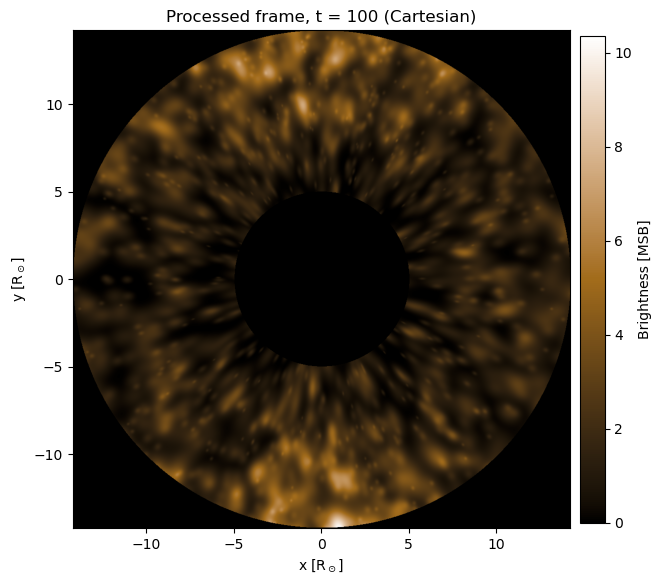

In [15]:
plot_rect_image(rect_img, title=f"Processed frame, t = {frame} (Cartesian)", cmap=cmap_punch,
                label="Brightness [MSB]")

## ⚠️ Why this version (v2-fixed) was not ideal

**The blobs run out before the end of the simulation.**

The frame above is $t = 100$ of 300. It is already sparse and dim, and the later frames get emptier. In `syncom_image` (v2), each blob is drawn as a fixed train of 7 copies ($n = 0, \pm2, \pm4, \pm6$) that moves outward rigidly. **No new copy is ever released.** Once the 7 copies of a blob have crossed the top of the field, that position angle stays dark for the rest of the run.

Copies inside the field (2000 blobs, 7 copies each = 14000):

| frame | 0 | 100 | 200 | 299 |
|---|---|---|---|---|
| copies in the field | 3425 | 1804 | 303 | 3 |

By the last frames almost nothing is left. That isn't what the model is meant to represent: a periodic source keeps releasing a blob **every time its period is up**, for as long as it is observed. A second problem makes it worse. Blobs start at about 9.9 R☉ instead of 5 R☉, so the inner half of the field is never filled by new material.

**So a fix was needed.** In **v3-periodic_blobs**:
- every blob is launched again from 5 R☉ each time its period is up, for the whole run
- the number of visible launches stays at about 9000 from frame ≈100 to the last frame
- the frame-100 Cartesian image is filled from 5 R☉ to 14.2 R☉

See the `v3-periodic_blobs` version of this notebook and `syncom_notebook_tests.ipynb`.


## Cartesian movie: `save_rect_movie`

### What it does
`save_rect_movie(cube, filename, start_time, title, fps)` converts every frame with `polar_to_rect` and writes an MP4. Every frame uses the same colour scale, and the occulter and corners are black.

### Expected behaviour
- `SynCOM_runs/<run>/movies/<run>_rect_movie.mp4`, about 1–2 MB for 300 frames.
- It looks like a coronagraph movie: blobs stream out of the occulter edge in every direction, faster in the fast sectors.


In [16]:
rect_title = f"{RUN_NAME}_rect"
save_rect_movie(
    cube,
    filename=syncom_output_path(RUN_NAME, "movies", "rect_movie.mp4"),
    start_time=START_TIME,
    title=rect_title,
    fps=10,
    # frames=range(0, 100),   # only part of the cube
)

2026-11-07 15:35:38 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x1110 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4


  50/300 frames (4 s)
  100/300 frames (8 s)
  150/300 frames (13 s)
  200/300 frames (17 s)
  250/300 frames (21 s)
  300/300 frames (25 s)
✅ Saved movie: SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4 (300 frames at 10 fps)


PosixPath('SynCOM_runs/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0/movies/SynCOM_v1-fixed_N_BLOBS_2000_SCALE_FACTOR_2.0_rect_movie.mp4')

## Conclusion: a fix was needed
This movie shows the main problem of v2-fixed: **the blobs run out before the end of the simulation**. The field starts reasonably full and slowly goes dark, because each blob has only 7 copies and is never launched again. The next version, **v3-periodic_blobs**, launches every blob again each time its period is up, from 5 R☉, so the corona stays filled for the whole run.
